# 2. Document-level analysis

Applies the final classifier to all pivot sentences of the 34 documents with 800–899 examples
and compares the predicted noise rate of each document with the BnF OCR score.

Reproduces Table 5, Figures 1 and 2, and the correlation coefficients of Section 3 of the paper.
Run `1_train_classifier.ipynb` first.

In [11]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from scipy.stats import pearsonr, spearmanr

from ocr_metrics import add_features

DATA_DIR = Path("../data")
OUTPUT_DIR = Path("../outputs")

PERIODS = [(1650, 1779), (1780, 1840), (1841, 1913), (1914, 2020)]
PERIOD_COLORS = {
    "1650-1779": "#4C72B0",
    "1780-1840": "#DD8452",
    "1841-1913": "#55A868",
    "1914-2020": "#C44E52",
}

In [12]:
artifact = joblib.load(OUTPUT_DIR / "best_model.pkl")
scaler, model, feature_cols = artifact["scaler"], artifact["model"], artifact["feature_cols"]
feature_cols

['Gain_Score_OOV',
 'Gain_Score_Perplexite_log',
 'Score_OOV_apres',
 'Perplexite_log']

## Data and features

This step computes perplexity for ~57,000 sentences (original and corrected) and takes a while on CPU.

In [13]:
docs = pd.read_csv(DATA_DIR / "slices_800-900.tsv", sep="\t", dtype={"doc_id": str})
print(docs.shape)

docs = add_features(docs)
docs = docs.dropna(subset=["Score_OOV_avant", "Score_Perplexite_avant",
                           "Score_OOV_apres", "Score_Perplexite_apres"])
print(docs.shape)
docs.to_csv(OUTPUT_DIR / "slices_800-900_with_features.csv", index=False)

(28488, 10)
(28488, 18)


## Prediction

In [14]:
# Use the scaler fitted on the training data (do not refit).
docs["prediction"] = model.predict(scaler.transform(docs[feature_cols]))

In [15]:
def assign_period(year):
    for lo, hi in PERIODS:
        if lo <= year <= hi:
            return f"{lo}-{hi}"
    return "out_of_range"


# Periods are assigned from the corrected publication date, not from the source directory.
docs["period"] = docs["Date_correction"].apply(assign_period)

by_doc = (
    docs.groupby("doc_id")
    .agg(
        n_examples=("prediction", "size"),
        class0_rate=("prediction", lambda x: (x == 0).mean()),
        period=("period", "first"),
        year=("Date_correction", "first"),
    )
    .reset_index()
    .sort_values("year")
    .reset_index(drop=True)
)
by_doc

,doc_id,n_examples,class0_rate,period,year
0,5831702,804,0.573383,1650-1779,1758
1,9765106,863,0.264195,1650-1779,1765
2,0208093,875,0.068571,1780-1840,1789
3,5835495,882,0.475057,1780-1840,1790
4,9632977,804,0.149254,1780-1840,1798
5,9633241,815,0.152147,1780-1840,1800
6,5813141,817,0.069767,1780-1840,1819
7,4221547,817,0.107711,1780-1840,1823
8,5493983,847,0.332940,1780-1840,1832
9,5816002,848,0.332547,1780-1840,1838


In [16]:
# Table 5 and per-period statistics (rates are means over documents)
summary = by_doc.groupby("period").agg(
    documents=("doc_id", "size"),
    examples=("n_examples", "sum"),
    mean_class0_rate=("class0_rate", "mean"),
    min_class0_rate=("class0_rate", "min"),
    max_class0_rate=("class0_rate", "max"),
)
print(summary.round(3))
print("Overall mean over documents: {:.1%}".format(by_doc["class0_rate"].mean()))

           documents  examples  mean_class0_rate  min_class0_rate  \
period                                                              
1650-1779          2      1667             0.419            0.264   
1780-1840         10      8379             0.198            0.069   
1841-1913         18     15044             0.098            0.033   
1914-2020          4      3398             0.077            0.038   

           max_class0_rate  
period                      
1650-1779            0.573  
1780-1840            0.475  
1841-1913            0.226  
1914-2020            0.122  
Overall mean over documents: 14.4%


## Figure 1: predicted noise rate per document

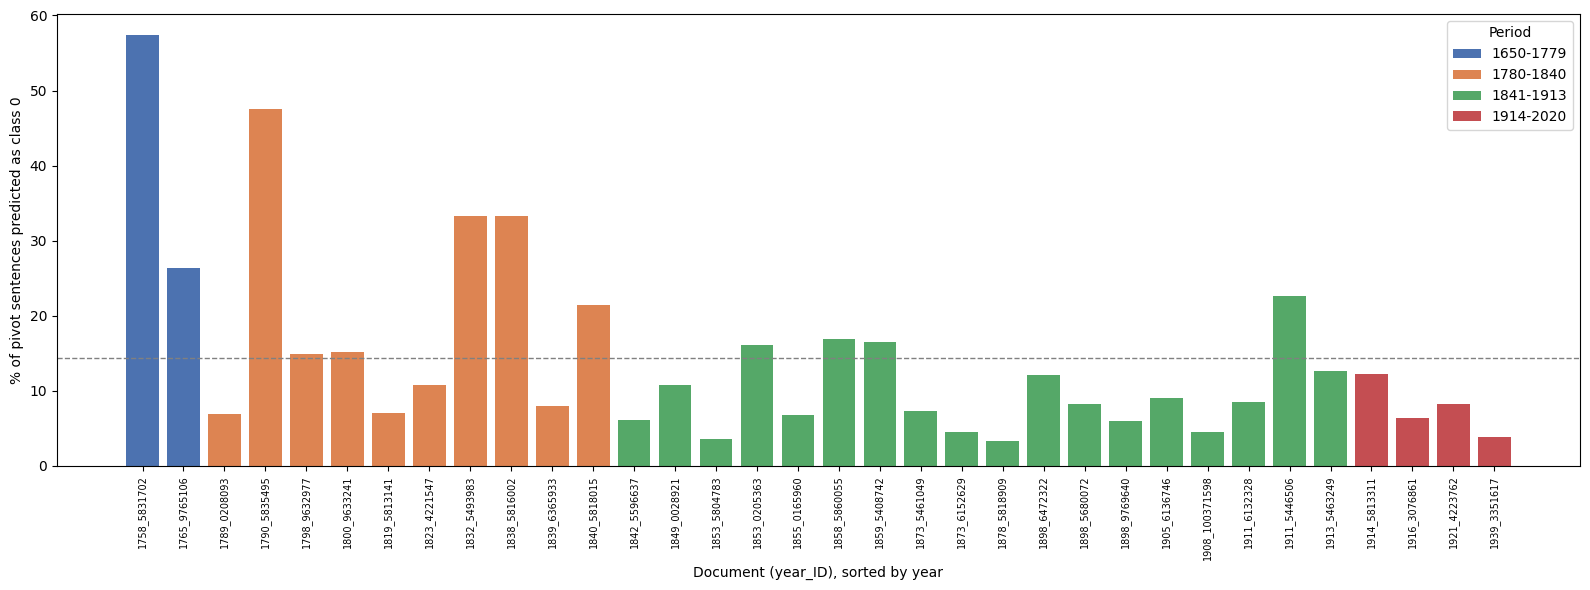

In [20]:
fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(range(len(by_doc)), by_doc["class0_rate"] * 100, color=by_doc["period"].map(PERIOD_COLORS))
ax.axhline(by_doc["class0_rate"].mean() * 100, color="gray", linestyle="--", linewidth=1)

ax.set_xticks(range(len(by_doc)))
ax.set_xticklabels(by_doc["year"].astype(str) + "_" + by_doc["doc_id"], rotation=90, fontsize=7)
ax.set_ylabel("% of pivot sentences predicted as class 0")
ax.set_xlabel("Document (year_ID), sorted by year")
ax.legend(handles=[Patch(facecolor=c, label=p) for p, c in PERIOD_COLORS.items()],
          title="Period", loc="upper right")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "noise_rate.png", dpi=150, bbox_inches="tight")
plt.show()

## Comparison with the BnF OCR score

The BnF score is a document-level constant. It is stored as text with either a decimal comma
or a decimal point (e.g. `90,445`, `98.5`).

In [21]:
docs["OCR_num"] = docs["OCR"].astype(str).str.replace(",", ".", regex=False).astype(float)
by_doc["OCR"] = by_doc["doc_id"].map(docs.groupby("doc_id")["OCR_num"].first())

print("Documents without a BnF score:", by_doc["OCR"].isna().sum(), "/", len(by_doc))
with_score = by_doc.dropna(subset=["OCR"])

r, p_r = pearsonr(with_score["OCR"], with_score["class0_rate"])
rho, p_rho = spearmanr(with_score["OCR"], with_score["class0_rate"])
print(f"n = {len(with_score)}")
print(f"Pearson r  = {r:.3f} (p = {p_r:.3f})")
print(f"Spearman ρ = {rho:.3f} (p = {p_rho:.3f})")

Documents without a BnF score: 3 / 34
n = 31
Pearson r  = -0.563 (p = 0.001)
Spearman ρ = -0.506 (p = 0.004)


## Figure 2: BnF OCR score vs. predicted noise rate

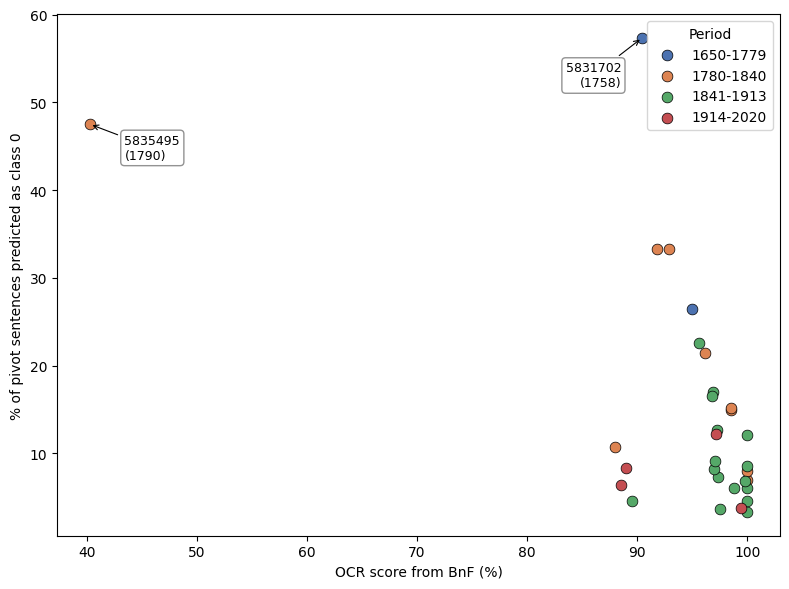

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
for period, color in PERIOD_COLORS.items():
    subset = with_score[with_score["period"] == period]
    ax.scatter(subset["OCR"], subset["class0_rate"] * 100, color=color, label=period,
               s=60, edgecolor="black", linewidth=0.5)

# Documents discussed in the paper
annotations = {
    "5831702": dict(xytext=(-15, -35), ha="right"),
    "5835495": dict(xytext=(25, -25), ha="left"),
}
for doc_id, style in annotations.items():
    row = with_score[with_score["doc_id"] == doc_id].iloc[0]
    ax.annotate(f"{doc_id}\n({row['year']})", xy=(row["OCR"], row["class0_rate"] * 100),
                textcoords="offset points", fontsize=9,
                arrowprops=dict(arrowstyle="->", lw=0.8, color="black"),
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.85),
                **style)

ax.set_xlabel("OCR score from BnF (%)")
ax.set_ylabel("% of pivot sentences predicted as class 0")
ax.legend(title="Period")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "corr.png", dpi=150, bbox_inches="tight")
plt.show()